# Análise de vendas, entregas e satisfação — Olist

**Autor:** Martino Lamaison  
**Curso:** EBAC — Analista de Dados

## Objetivo
Analisar as vendas da Olist para identificar as principais categorias de produtos, a distribuição das vendas por estado e a relação entre o prazo de entrega e a avaliação dos clientes.

## Base de dados
Utilizei a base pública Brazilian E-Commerce Public Dataset by Olist, disponível no [Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), com registros de 2016 a 2018.

A base reúne informações sobre pedidos, clientes, produtos, itens vendidos, pagamentos e avaliações. Os resultados se referem aos registros da Olist nesse período.

## Perguntas da análise
- Como o valor das vendas variou ao longo dos meses?
- Quais categorias e estados concentraram as vendas?
- Como os valores dos pedidos se distribuem?
- Qual é a relação entre o prazo de entrega e a nota dos clientes?
- Qual é o peso do frete e a participação de cada meio de pagamento?

## Como executar
Mantenha a estrutura de pastas do projeto e abra este notebook no VS Code ou Jupyter. Com as bibliotecas pandas, numpy e matplotlib instaladas, execute as células na ordem apresentada.

## Dashboard
O dashboard interativo está disponível no [Looker Studio](https://datastudio.google.com/s/pu27TV9PNkg).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10,4.8), 'axes.spines.top':False, 'axes.spines.right':False, 'axes.titleweight':'bold', 'axes.labelsize':11})
for pasta in ['dados_tratados','looker','resultados','graficos']: Path(pasta).mkdir(exist_ok=True)
nomes=['orders','order_items','products','customers','order_payments','order_reviews','sellers']
raw={n:pd.read_csv(f'dados_brutos/olist_{n}_dataset.csv',dtype={c:'string' for c in ['customer_zip_code_prefix','seller_zip_code_prefix']}) for n in nomes}
inventario=pd.DataFrame([{'tabela':n,'linhas':len(d),'colunas':len(d.columns),'duplicatas_exatas':int(d.duplicated().sum()),'celulas_nulas':int(d.isna().sum().sum())} for n,d in raw.items()])
print(inventario.to_string(index=False))
assert len(raw)>=3 and (inventario.colunas>5).sum()>=2 and (inventario.linhas>100).sum()>=2
inventario.to_csv('resultados/inventario.csv',index=False)
auditoria=pd.concat([d.isna().sum().rename('nulos').reset_index().assign(tabela=n) for n,d in raw.items()],ignore_index=True)
auditoria.to_csv('resultados/nulos_originais.csv',index=False)


        tabela  linhas  colunas  duplicatas_exatas  celulas_nulas
        orders   99441        8                  0           4908
   order_items  112650        7                  0              0
      products   32951        9                  0           2448
     customers   99441        5                  0              0
order_payments  103886        5                  0              0
 order_reviews   99224        7                  0         145903
       sellers    3095        4                  0              0


## 1. Qualidade e preparação dos dados

Primeiro, verifiquei valores ausentes, duplicatas, tipos de dados e possíveis inconsistências nas tabelas.

Na tabela de pedidos, cada linha representa um pedido, que pode ter vários itens, pagamentos e avaliações nas outras tabelas. Mantive os identificadores e os CEPs como texto.

Adotei os seguintes critérios de tratamento:
- Remover apenas duplicatas exatas, quando encontradas.
- Converter datas inválidas em valores ausentes e registrar essas ocorrências.
- Preencher categorias ausentes com “sem categoria”.
- Manter medidas físicas e comentários ausentes sem preenchimento.
- Preservar datas de entrega ausentes, pois podem corresponder a pedidos cancelados ou ainda não entregues.
- Excluir intervalos negativos apenas dos cálculos de prazo, mantendo os registros para as demais análises.

Também conferi se as avaliações estavam entre 1 e 5 e se os preços e fretes apresentavam valores negativos.

In [2]:
d={n:t.drop_duplicates().copy() for n,t in raw.items()}
log=[]
for n,t in d.items():
    for c in t.columns:
        if c.endswith('_id'):
            t[c]=t[c].astype('string').str.strip()
        if c.endswith('_date') or c.endswith('_at') or c=='order_purchase_timestamp':
            old=t[c].notna().sum();t[c]=pd.to_datetime(t[c],errors='coerce')
            log.append({'tabela':n,'campo':c,'datas_invalidas':int(old-t[c].notna().sum())})
for n in ['customers','sellers']:
    pref='customer' if n=='customers' else 'seller'
    d[n][pref+'_state']=d[n][pref+'_state'].str.strip().str.upper()
    d[n][pref+'_city']=d[n][pref+'_city'].str.strip().str.lower()
    d[n][pref+'_zip_code_prefix']=d[n][pref+'_zip_code_prefix'].str.zfill(5)
d['products']['product_category_name']=d['products']['product_category_name'].fillna('sem_categoria').str.strip().str.lower().str.replace('_',' ',regex=False)
for c in ['review_comment_title','review_comment_message']:
    d['order_reviews'][c]=d['order_reviews'][c].fillna('')
assert d['order_reviews'].review_score.between(1,5).all()
assert (d['order_items'][['price','freight_value']]>=0).all().all()
assert (d['order_payments'].payment_value>=0).all()
for n,k in [('orders',['order_id']),('products',['product_id']),('customers',['customer_id']),('sellers',['seller_id']),('order_items',['order_id','order_item_id'])]:
    assert not d[n].duplicated(k).any(), (n,'chave duplicada')
    assert not d[n][k].isna().any().any()
print(pd.DataFrame(log).to_string(index=False))
pd.DataFrame(log).to_csv('resultados/conversao_datas.csv',index=False)
for n,t in d.items(): t.to_csv(f'dados_tratados/{n}.csv',index=False,date_format='%Y-%m-%d %H:%M:%S')


       tabela                         campo  datas_invalidas
       orders      order_purchase_timestamp                0
       orders             order_approved_at                0
       orders  order_delivered_carrier_date                0
       orders order_delivered_customer_date                0
       orders order_estimated_delivery_date                0
  order_items           shipping_limit_date                0
order_reviews          review_creation_date                0


## 2. Cruzamentos e métricas derivadas

Somei os valores dos itens e dos pagamentos por pedido antes de juntar as tabelas. Isso evita repetir valores quando um pedido possui vários itens ou pagamentos.

Quando havia mais de uma avaliação para o mesmo pedido, selecionei a mais recente pela data de resposta. Em caso de empate, utilizei a data de criação e o identificador da avaliação.

Criei colunas para apoiar a análise, como:
- **Valor com frete:** valor dos produtos mais o frete.
- **Prazo em dias:** tempo entre a compra e a entrega.
- **Dias de atraso:** diferença entre a entrega realizada e a prevista.
- **Mês da compra:** agrupamento das compras por ano e mês.

O valor dos produtos corresponde à soma do campo `price`. A base não possui informações suficientes para calcular lucro ou receita líquida.

Nas análises de vendas, considerei apenas pedidos entregues (`delivered`). Para analisar a situação dos pedidos, mantive todos os status.

Na evolução mensal, utilizei janeiro de 2017 a agosto de 2018, pois os meses anteriores possuem poucos registros. O último mês também pode estar incompleto devido ao encerramento da coleta.

In [3]:
o=d['orders'];i=d['order_items'];p=d['order_payments'];r=d['order_reviews']
integridade=[]
for filha,chave,pai in [('order_items','order_id','orders'),('order_payments','order_id','orders'),('order_reviews','order_id','orders'),('orders','customer_id','customers'),('order_items','product_id','products'),('order_items','seller_id','sellers')]:
    faltas=int((~d[filha][chave].isin(d[pai][chave])).sum())
    integridade.append({'filha':filha,'chave':chave,'pai':pai,'sem_correspondencia':faltas})
    assert faltas==0
print(pd.DataFrame(integridade).to_string(index=False))
pd.DataFrame(integridade).to_csv('resultados/integridade.csv',index=False)
it=i.groupby('order_id',as_index=False).agg(valor_produtos=('price','sum'),valor_frete=('freight_value','sum'),quantidade_itens=('order_item_id','size'))
pa=p.groupby('order_id',as_index=False).agg(valor_pago=('payment_value','sum'),registros_pagamento=('payment_value','size'))
print('Avaliações adicionais por pedido:',len(r)-r.order_id.nunique())
rv=r.sort_values(['review_answer_timestamp','review_creation_date','review_id'],na_position='first').drop_duplicates('order_id',keep='last')[['order_id','review_score']]
b=o.merge(d['customers'],on='customer_id',how='left',validate='many_to_one').merge(it,on='order_id',how='left',validate='one_to_one').merge(pa,on='order_id',how='left',validate='one_to_one').merge(rv,on='order_id',how='left',validate='one_to_one')
assert len(b)==len(o) and b.order_id.is_unique
assert np.isclose(b.valor_produtos.sum(),i.price.sum())
assert np.isclose(b.valor_pago.sum(),p.payment_value.sum())
b['data_compra']=b.order_purchase_timestamp.dt.strftime('%Y%m%d')
b['mes_compra']=b.order_purchase_timestamp.dt.to_period('M').astype(str)
b['valor_com_frete']=b.valor_produtos+b.valor_frete
b['prazo_dias']=(b.order_delivered_customer_date-b.order_purchase_timestamp).dt.total_seconds()/86400
b['prazo_invalido']=b.prazo_dias.lt(0).astype(int)
b.loc[b.prazo_dias<0,'prazo_dias']=np.nan
b['dias_atraso']=(b.order_delivered_customer_date.dt.normalize()-b.order_estimated_delivery_date.dt.normalize()).dt.days
valida=b.order_status.eq('delivered') & b.dias_atraso.notna() & b.prazo_dias.notna()
b['atrasado']=np.where(valida,(b.dias_atraso>0).astype(float),np.nan)
b['situacao_entrega']=np.where(valida,np.where(b.dias_atraso>0,'Com atraso','No prazo'),'Sem prazo válido')
b['proporcao_frete']=b.valor_frete.div(b.valor_com_frete.where(b.valor_com_frete>0))
b['estado']=b.customer_state
b['estado_iso']='BR-'+b.estado
v=b[b.order_status.eq('delivered')].copy()
v['faixa_valor']=pd.cut(v.valor_produtos,bins=[-0.01,50,100,200,500,1000,np.inf],labels=['01. Até 50','02. 50–100','03. 100–200','04. 200–500','05. 500–1000','06. Acima de 1000']).astype('string')
j=i.merge(d['products'],on='product_id',how='left',validate='many_to_one').merge(v[['order_id','data_compra','estado','estado_iso']],on='order_id',how='inner',validate='many_to_one')
print('Pedidos por status:');print(b.order_status.value_counts().to_string())
print('Pedidos entregues sem itens:',int(v.valor_produtos.isna().sum()))
print('Pedidos sem pagamentos:',int(b.valor_pago.isna().sum()))
print('Prazos negativos sinalizados:',int(b.prazo_invalido.sum()))
print('Entregues sem prazo válido:',int(v.atrasado.isna().sum()))
b.to_csv('dados_tratados/pedidos_consolidados.csv',index=False)


         filha       chave       pai  sem_correspondencia
   order_items    order_id    orders                    0
order_payments    order_id    orders                    0
 order_reviews    order_id    orders                    0
        orders customer_id customers                    0
   order_items  product_id  products                    0
   order_items   seller_id   sellers                    0
Avaliações adicionais por pedido: 551
Pedidos por status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Pedidos entregues sem itens: 0
Pedidos sem pagamentos: 1
Prazos negativos sinalizados: 0
Entregues sem prazo válido: 8


## 3. Distribuição dos valores dos pedidos

Analisei o valor dos produtos por pedido entregue, comparando a média, a mediana e a distribuição dos valores.

Para identificar valores extremos, utilizei a regra de 1,5 vez o intervalo interquartil. Mantive esses pedidos na análise, pois um valor alto, por si só, não indica erro.

No histograma, exibi os valores até o percentil 99 para facilitar a leitura. Os cálculos das estatísticas incluem todos os pedidos entregues.

count    96478.000000
mean       137.041586
std        209.045198
min          0.850000
25%         45.900000
50%         86.575000
75%        149.900000
95%        399.000000
99%        990.000000
max      13440.000000
Limite superior IQR: R$ 305.90; pedidos acima: 7659 (7.94%)


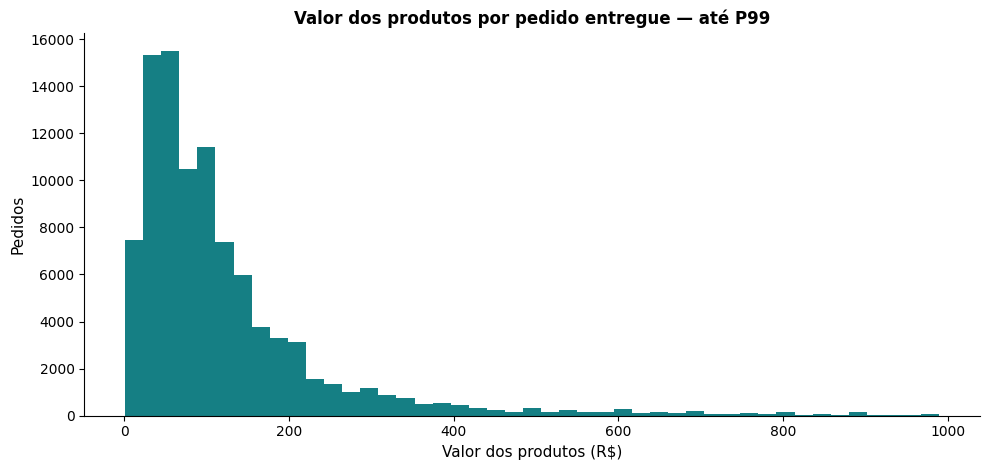

In [4]:
desc=v.valor_produtos.describe(percentiles=[.25,.5,.75,.95,.99]);print(desc.to_string())
q1,q3=v.valor_produtos.quantile([.25,.75]);lim=q3+1.5*(q3-q1)
extremos=int((v.valor_produtos>lim).sum())
print(f'Limite superior IQR: R$ {lim:.2f}; pedidos acima: {extremos} ({extremos/len(v):.2%})')
desc.to_csv('resultados/distribuicao.csv')
fig,ax=plt.subplots();v.loc[v.valor_produtos<=desc['99%'],'valor_produtos'].hist(bins=45,ax=ax,color='#157f84',grid=False)
ax.set(title='Valor dos produtos por pedido entregue — até P99',xlabel='Valor dos produtos (R$)',ylabel='Pedidos');fig.tight_layout();fig.savefig('graficos/01_distribuicao.png',dpi=150)


## 4. Evolução mensal das vendas

Agrupei o valor dos produtos por mês da compra para acompanhar a evolução das vendas entre janeiro de 2017 e agosto de 2018.

As variações podem estar relacionadas a mudanças no volume de pedidos e na cobertura da Olist. A base, sozinha, não permite confirmar se os picos foram causados por campanhas ou sazonalidade.

            valor_produtos  pedidos  ticket_medio
mes_compra                                       
2017-01          111798.36      750    149.064480
2017-02          234223.40     1653    141.695947
2017-03          359198.85     2546    141.083602
2017-04          340669.68     2303    147.924307
2017-05          489338.25     3546    137.997250
2017-06          421923.37     3135    134.584807
2017-07          481604.52     3872    124.381333
2017-08          554699.70     4193    132.291844
2017-09          607399.67     4150    146.361366
2017-10          648247.65     4478    144.762762
2017-11          987765.37     7289    135.514525
2017-12          726033.19     5513    131.694756
2018-01          924645.00     7069    130.802801
2018-02          826437.13     6555    126.077365
2018-03          953356.25     7003    136.135406
2018-04          973534.09     6798    143.208898
2018-05          977544.69     6749    144.842894
2018-06          856077.86     6099    140.363643


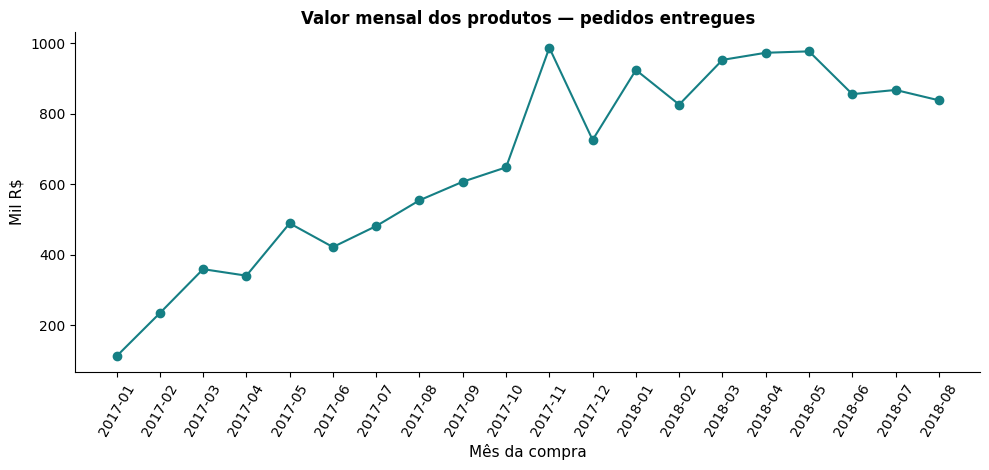

In [5]:
mensal=v.groupby('mes_compra').agg(valor_produtos=('valor_produtos','sum'),pedidos=('order_id','nunique'))
mensal=mensal.loc['2017-01':'2018-08'];mensal['ticket_medio']=mensal.valor_produtos/mensal.pedidos
print(mensal.to_string());mensal.to_csv('resultados/mensal.csv')
fig,ax=plt.subplots();ax.plot(mensal.index,mensal.valor_produtos/1000,marker='o',color='#157f84');ax.tick_params(axis='x',rotation=60)
ax.set(title='Valor mensal dos produtos — pedidos entregues',ylabel='Mil R$',xlabel='Mês da compra');fig.tight_layout();fig.savefig('graficos/02_mensal.png',dpi=150)


## 5. Vendas por categoria e estado

Comparei o valor dos produtos por categoria e por estado para identificar onde as vendas se concentram.

Para as categorias, somei o valor de cada item vendido. Para os estados, considerei a localização do cliente.

Um pedido pode conter produtos de categorias diferentes. Por isso, a soma das contagens de pedidos por categoria pode superar o total de pedidos únicos.

Categorias líderes:
                        valor_produtos  itens  pedidos
product_category_name                                 
beleza saude                1233131.72   9465     8647
relogios presentes          1166176.98   5859     5495
cama mesa banho             1023434.76  10953     9272
esporte lazer                954852.55   8431     7530
informatica acessorios       888724.61   7644     6530
moveis decoracao             711927.69   8160     6307
utilidades domesticas        615628.69   6795     5743
cool stuff                   610204.10   3718     3559
automotivo                   578966.65   4140     3810
brinquedos                   471286.48   4030     3804
Estados líderes:
        valor_produtos  pedidos  ticket_medio
estado                                       
SP          5067633.16    40501    125.123655
RJ          1759651.13    12350    142.481873
MG          1552481.83    11354    136.734352
RS           728897.47     5345    136.369966
PR           666063.51     

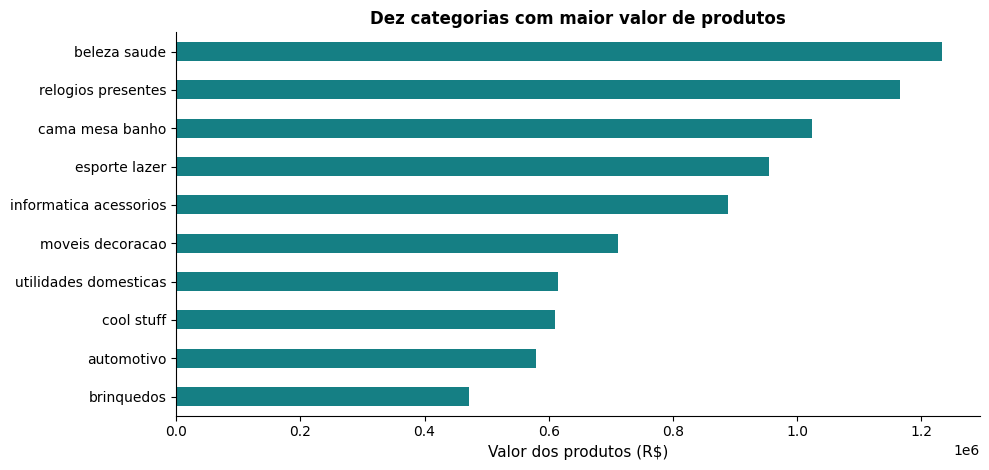

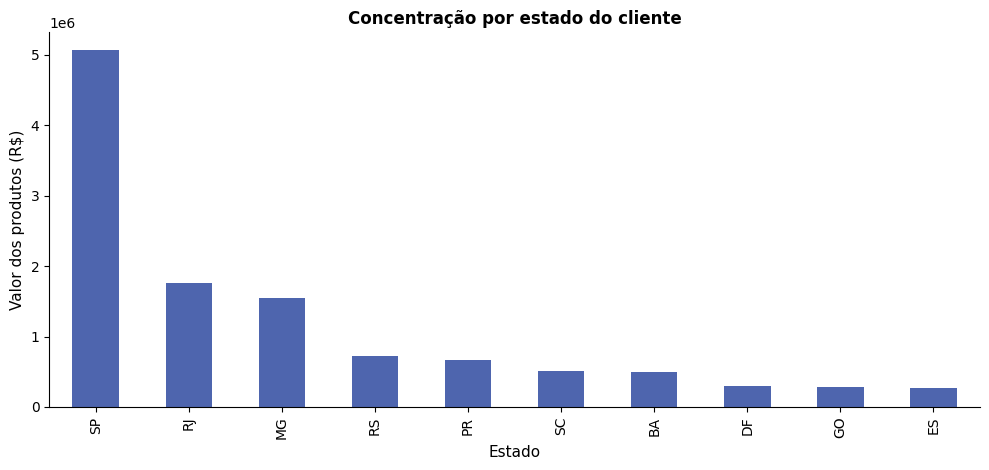

In [6]:
cat=j.groupby('product_category_name').agg(valor_produtos=('price','sum'),itens=('order_item_id','size'),pedidos=('order_id','nunique')).sort_values('valor_produtos',ascending=False)
est=v.groupby('estado').agg(valor_produtos=('valor_produtos','sum'),pedidos=('order_id','nunique'),ticket_medio=('valor_produtos','mean')).sort_values('valor_produtos',ascending=False)
print('Categorias líderes:');print(cat.head(10).to_string());print('Estados líderes:');print(est.head(10).to_string())
cat.to_csv('resultados/categorias.csv');est.to_csv('resultados/estados.csv')
fig,ax=plt.subplots();cat.head(10).iloc[::-1].valor_produtos.plot.barh(ax=ax,color='#157f84');ax.set(title='Dez categorias com maior valor de produtos',xlabel='Valor dos produtos (R$)',ylabel='');fig.tight_layout();fig.savefig('graficos/03_categorias.png',dpi=150)
fig,ax=plt.subplots();est.head(10).valor_produtos.plot.bar(ax=ax,color='#4e65ae');ax.set(title='Concentração por estado do cliente',xlabel='Estado',ylabel='Valor dos produtos (R$)');fig.tight_layout();fig.savefig('graficos/04_estados.png',dpi=150)


## 6. Prazo de entrega e satisfação dos clientes

Comparei as notas dos clientes entre pedidos entregues no prazo e com atraso. Considerei como atraso a entrega realizada após o dia previsto; entregas no dia previsto foram classificadas como pontuais.

Utilizei apenas pedidos entregues com datas válidas e avaliação disponível.

Também calculei a correlação de Spearman entre o tempo de entrega e a nota do cliente para verificar se prazos maiores estão associados a notas menores. Essa relação não permite afirmar que o prazo foi a causa da avaliação.

                  pedidos  nota_media  nota_mediana  prazo_medio
situacao_entrega                                                
Com atraso           6381    2.270491           1.0    33.823558
No prazo            89443    4.290386           5.0    10.996706
Spearman prazo x nota: -0.235; n=95824


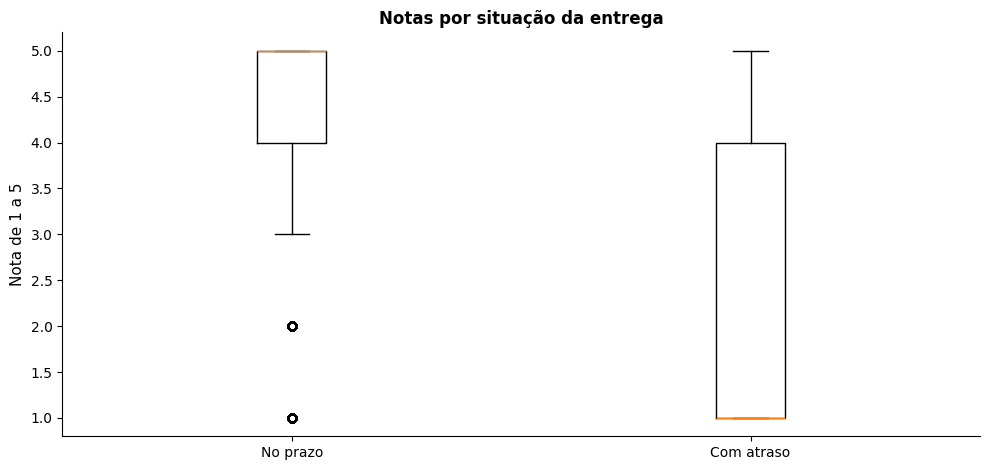

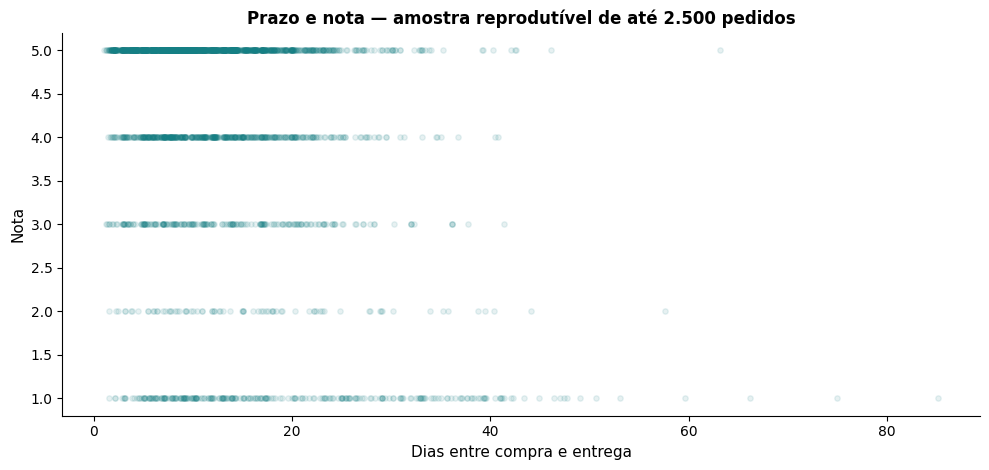

In [7]:
aval=v.dropna(subset=['atrasado','review_score','prazo_dias'])
sat=aval.groupby('situacao_entrega').agg(pedidos=('order_id','size'),nota_media=('review_score','mean'),nota_mediana=('review_score','median'),prazo_medio=('prazo_dias','mean'))
# Correlação de Pearson entre postos = Spearman, sem dependência de scipy.
rho=aval[['prazo_dias','review_score']].rank().corr().iloc[0,1]
print(sat.to_string());print(f'Spearman prazo x nota: {rho:.3f}; n={len(aval)}')
sat.to_csv('resultados/satisfacao.csv')
fig,ax=plt.subplots();ax.boxplot([aval.loc[aval.situacao_entrega==g,'review_score'] for g in ['No prazo','Com atraso']],tick_labels=['No prazo','Com atraso']);ax.set(title='Notas por situação da entrega',ylabel='Nota de 1 a 5');fig.tight_layout();fig.savefig('graficos/05_notas.png',dpi=150)
amostra=aval.sample(min(2500,len(aval)),random_state=42)
fig,ax=plt.subplots();ax.scatter(amostra.prazo_dias,amostra.review_score,alpha=.10,s=15,color='#157f84');ax.set(title='Prazo e nota — amostra reprodutível de até 2.500 pedidos',xlabel='Dias entre compra e entrega',ylabel='Nota');fig.tight_layout();fig.savefig('graficos/06_dispersao.png',dpi=150)


## 7. Participação do frete e meios de pagamento

Calculei a participação do frete no valor total dos pedidos, dividindo a soma dos fretes pela soma do valor dos produtos mais o frete. Esse cálculo representa o peso do frete no conjunto das vendas.

Também comparei o valor pago por meio de pagamento, utilizando a tabela de pagamentos. Um mesmo pedido pode ter mais de um registro ou utilizar diferentes meios de pagamento.

Peso agregado do frete: 14.26%
               valor_pago  registros  pedidos
payment_type                                 
credit_card   12101094.88      74586    74304
boleto         2769932.58      19191    19191
voucher         343013.19       5493     3679
debit_card      208421.12       1486     1485


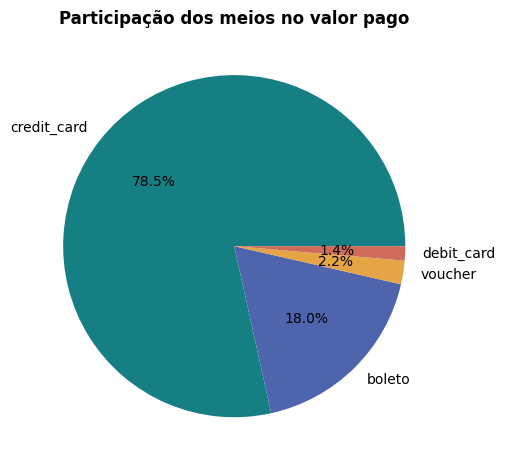

In [8]:
frete=v.valor_frete.sum()/v.valor_com_frete.sum()
pay=p[p.order_id.isin(v.order_id)].groupby('payment_type').agg(valor_pago=('payment_value','sum'),registros=('payment_value','size'),pedidos=('order_id','nunique')).sort_values('valor_pago',ascending=False)
print(f'Peso agregado do frete: {frete:.2%}');print(pay.to_string())
pay.to_csv('resultados/pagamentos.csv')
fig,ax=plt.subplots();pay.valor_pago.plot.pie(ax=ax,autopct='%1.1f%%',ylabel='',colors=['#157f84','#4e65ae','#e5a546','#cf6b58','#aaaaaa']);ax.set_title('Participação dos meios no valor pago');fig.tight_layout();fig.savefig('graficos/07_pagamentos.png',dpi=150)


## 8. Exportação dos dados e dashboard

Após o tratamento e os cruzamentos em Python, exportei os dados em arquivos CSV:

- **looker_pedidos:** uma linha por pedido entregue.
- **looker_itens:** uma linha por item de pedido entregue.
- **looker_pagamentos:** uma linha por registro de pagamento de pedidos entregues.
- **looker_status:** todos os pedidos, incluindo os demais status.

No Looker Studio, utilizei pedidos, itens e pagamentos como fontes separadas, sem novos cruzamentos. Converti as datas exportadas no formato `YYYYMMDD` para o tipo Data.

Os valores monetários foram somados, as notas e os prazos foram calculados pela média e os pedidos foram contados por identificador distinto. Para a taxa de atraso, utilizei a média do indicador `atrasado` (0 ou 1), desconsiderando os registros sem informação válida.

Organizei o dashboard em duas páginas: **Vendas e Entregas** e **Produtos e Pagamentos**, com filtros para explorar os resultados.

[Consultar o dashboard no Looker Studio](https://datastudio.google.com/s/pu27TV9PNkg)

In [9]:
cols=['order_id','customer_unique_id','data_compra','mes_compra','estado','estado_iso','valor_produtos','valor_frete','valor_com_frete','quantidade_itens','review_score','prazo_dias','dias_atraso','atrasado','situacao_entrega','proporcao_frete','faixa_valor']
v[cols].to_csv('looker/looker_pedidos.csv',index=False)
j[['order_id','order_item_id','product_id','data_compra','estado','estado_iso','product_category_name','price','freight_value']].to_csv('looker/looker_itens.csv',index=False)
lp=p.merge(v[['order_id','data_compra','estado']],on='order_id',how='inner',validate='many_to_one')
lp.to_csv('looker/looker_pagamentos.csv',index=False)
b[['order_id','data_compra','estado','order_status']].to_csv('looker/looker_status.csv',index=False)
assert np.isclose(j.price.sum(),v.valor_produtos.sum())
print('Controles para validar o dashboard sem filtros:')
metricas={'pedidos_entregues':len(v),'valor_produtos':round(v.valor_produtos.sum(),2),'ticket_medio_produtos':round(v.valor_produtos.mean(),2),'valor_frete':round(v.valor_frete.sum(),2),'taxa_atraso':float(v.atrasado.mean()),'nota_media':float(v.review_score.mean()),'prazo_medio_dias':float(v.prazo_dias.mean()),'peso_frete':float(frete),'spearman_prazo_nota':float(rho)}
print(pd.Series(metricas).to_string())
pd.Series(metricas).to_csv('resultados/controles_dashboard.csv',header=['valor'])
for f in Path('looker').glob('*.csv'):
    t=pd.read_csv(f);print(f.name,len(t), 'linhas',len(t.columns),'colunas')


Controles para validar o dashboard sem filtros:
pedidos_entregues        9.647800e+04
valor_produtos           1.322150e+07
ticket_medio_produtos    1.370400e+02
valor_frete              2.198276e+06
taxa_atraso              6.773090e-02
nota_media               4.155908e+00
prazo_medio_dias         1.255822e+01
peso_frete               1.425621e-01
spearman_prazo_nota     -2.345786e-01
looker_itens.csv 110197 linhas 9 colunas
looker_pagamentos.csv 100756 linhas 7 colunas
looker_pedidos.csv 96478 linhas 17 colunas
looker_status.csv 99441 linhas 4 colunas


## 9. Conclusões

- Os 96.478 pedidos entregues somaram R$ 13,22 milhões em produtos, com ticket médio de R$ 137,04 e mediana de R$ 86,57.
- Beleza e saúde liderou as vendas; as dez principais categorias concentraram 62,4% do valor.
- São Paulo representou 38,3% das vendas.
- Novembro de 2017 registrou o maior valor mensal analisado.
- Atrasos ocorreram em 6,77% das entregas com prazo válido. A nota média foi 4,29 nas pontuais e 2,27 nas atrasadas.
- O frete correspondeu a 14,26% do valor total com frete.

Os resultados indicam a importância de acompanhar as categorias líderes e os atrasos nas entregas. A base é histórica, não permite calcular lucro nem comprovar relações de causa e efeito.

[Dashboard no Looker Studio](https://datastudio.google.com/s/pu27TV9PNkg)